# 08 — Figure 2/3 Data Preparation

Shared workflow: read source files → apply scenario selections → convert SN observations to $D_M/r_d$ → propagate covariance → combine, validate, and export.

This notebook prepares data for the common PySR pipeline. Dependencies: numpy, pandas, PyYAML, and matplotlib. The two scenario configuration files select the supernova sample.

Updated on 2026-09-16: added an explicit audit of the full DESI covariance and its selected submatrices, clarified error conventions, and translated the notebook into English.

## 1. Environment and configuration

Find the project root by searching upward from the working directory. This supports execution from either the project root or the notebooks directory.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_ROOT = next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
                    if (p / "configs/fig2_pantheon.yaml").is_file())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from src.data_loading import (load_scenario_config, prepare_combined_dataset,
    save_standard_dataset, load_standard_dataset, load_desi_dm)

CONFIGS = {name: load_scenario_config(PROJECT_ROOT / "configs" / f"{name}.yaml")
           for name in ("fig2_pantheon", "fig3_desy5")}
print("Project:", PROJECT_ROOT)


Project: /Users/kemingliu/Desktop/Dark Energy


## 2. Sample definitions and selections

| Scenario | Observable | Selection | Raw → retained | Distance calibration |
|---|---|---|---|---|
| Pantheon+ | m_b_corr | zHD ≥ 0.01 | 1701 → 1590 light curves | M = −19.253; r_d = 138.28 Mpc |
| DESY5 | MU | MUERR_FINAL ≤ 1 | 1829 → 1754 SNe | H0 = 70; r_d = 101/0.7 Mpc |

Both scenarios include the same six transverse DESI DR2 BAO measurements. Preserve separate light curves of the same SN and the original catalog row order. Apply each selection to both axes of the covariance.

**Redshift conventions.** zHEL is the heliocentric redshift; zCMB includes the correction to the cosmic microwave background frame; zHD is the Hubble-diagram redshift with CMB and peculiar-velocity corrections. Nearby objects are especially affected by peculiar velocities relative to their cosmological recession, motivating the paper's z < 0.01 exclusion. The threshold is explicitly stated in the paper; the choice of the zHD column is our implementation convention. It reproduces the reported 1590 rows and redshift range 0.01016–2.26137. The paper does not explicitly identify that column.

**Release and covariance conventions.**

- [Pantheon+ release documentation](https://raw.githubusercontent.com/PantheonPlusSH0ES/DataRelease/main/Pantheon%2B_Data/4_DISTANCES_AND_COVAR/README): STAT+SYS already includes statistical covariance; do not add another diagonal statistical term.
- [Legacy DESY5 documentation, e3493cb](https://raw.githubusercontent.com/des-science/DES-SN5YR/e3493cb/4_DISTANCES_COVMAT/README.md): for the local 1829-row release, STAT+SYS.txt.gz contains additional systematic covariance. Add diag(MUERR_FINAL²) to obtain total covariance. The current DES-Dovekie branch uses a different release and must not be used to interpret these legacy files.

Source SHA-256 hashes identify the local inputs. They do not establish byte-for-byte agreement with a remote release.

## 3. Distance conversion and uncertainty propagation

For Pantheon+, set $\mu=m-M$; for DESY5, use the supplied MU. Then

$$y_i=\frac{10^{(\mu_i-25)/5}}{(1+z_{\rm HD,i})r_d},\qquad J_{ii}=\frac{\ln10}{5}y_i,\qquad C_y=J C_\mu J^T.$$

We use the single-redshift expression in Eq. (6), with zHD both as the fitting coordinate and in the denominator. This is an explicit reproduction convention rather than an author-confirmed column choice. Redshifts are fixed here; no extra peculiar-velocity variance is added on top of the released covariance.

### 3.1 Fixed calibration versus a shared calibration uncertainty

The exported covariance is a first-order approximation conditional on fixed calibration. All SNe share the same $r_d$: increasing the ruler length by 1% reduces every converted SN distance ratio by approximately 1%. This is a coherent shift, not independent noise for each SN.

For a future Monte Carlo calculation, draw one consistent ruler parameter per realization, use it for all SN conversions, and use the same realization in the cosmological parameter entering the $w(z)$ equation. Sample the observational covariance as well. The released BAO ratios are already measured dimensionless quantities and should not simply be divided by the sampled $r_d$ again.

The configurations retain the paper's rounded Pantheon+ Mpc values and the common $h^{-1}$ Mpc values separately. Reconcile that small rounding difference before joint sampling. The full magnitude-space covariance is also saved so that future simulations can draw correlated magnitudes directly; the nonlinear transformation need not be Gaussian in distance space.

BAO and SN observational errors are assumed independent here, giving two covariance blocks. Common calibration effects belong in later consistent sampling. No synthetic z=0 data point is added; enforce $D_M(0)=0$ in model space.

### 3.2 Small covariance asymmetry

A covariance must satisfy $C_{ij}=C_{ji}$. The local Pantheon+ text file contains differences up to $3\times10^{-8}$ mag². For example, 0.00048592 and 0.00048595 become 0.000485935 on both sides under

$$C_{\rm sym}=\frac{C+C^T}{2}.$$

This preserves the diagonal variances and observed central values. Only the derived matrix is changed; the source file is retained. The origin of this small asymmetry has not been established. Averaging is allowed only within an explicit $5\times10^{-8}$ mag² tolerance and is recorded in metadata. Larger discrepancies cause an error. No eigenvalue regularization is performed.

In [2]:
DATASETS = {name: prepare_combined_dataset(config) for name, config in CONFIGS.items()}
rows = []
for name, data in DATASETS.items():
    meta = data["metadata"]
    rows.append({"scenario": name, "raw_SN": meta["raw_sn_count"],
        "selected_SN": meta["selected_sn_count"], "BAO": meta["desi_count"],
        "combined": len(data["z"]), "SN_z_min": data["sn_z"].min(),
        "SN_z_max": data["sn_z"].max(),
        "covariance_shape": str(data["covariance"].shape),
        "positive_definite": meta["validation"]["positive_definite"]})
summary = pd.DataFrame(rows)
display(summary)


,scenario,raw_SN,selected_SN,BAO,combined,SN_z_min,SN_z_max,covariance_shape,positive_definite
0,fig2_pantheon,1701,1590,6,1596,0.01016,2.26137,"(1596, 1596)",True
1,fig3_desy5,1829,1754,6,1760,0.02509,1.12132,"(1760, 1760)",True


## 4. Full DESI covariance, selected measurements, and data checks

The local DESI release contains 13 observables and a 13 × 13 covariance: one $D_V/r_d$ at z=0.295, plus six pairs of $D_M/r_d$ and $D_H/r_d$.

- $D_M/r_d$ measures the transverse distance scale.
- $D_H/r_d=c/[H(z)r_d]$ measures the radial distance scale.
- $D_V/r_d$ combines transverse and radial information into an isotropic distance measure.

Figure 1 selects the six radial measurements. Figures 2 and 3 select the six transverse measurements and add different supernova samples. The $D_V/r_d$ measurement is not used in these reconstructions.

### 4.1 Standard deviation, correlation, and covariance

$$C_{ij}=\rho_{ij}\sigma_i\sigma_j,\qquad C_{ii}=\sigma_i^2.$$

Standard deviation describes an individual error scale. Correlation describes how two errors vary together; covariance combines both scales and their correlation. Correlated residuals should not be counted as independent evidence.

The covariance used here is supplied in the DESI release. The symbolic-regression pipeline extracts the selected submatrix; it does not estimate DESI correlations from scratch.

**Verified for the local files:** all nonzero off-diagonal entries couple $D_M/r_d$ and $D_H/r_d$ at the same redshift. Both the DM-only and DH-only 6 × 6 submatrices are exactly diagonal. Thus six standard deviations are sufficient to reconstruct either selected DESI covariance under the release's zero cross-bin correlation convention. Zero correlation in this release is not a general proof that all conceivable survey systematics are independent.

The following cell verifies these statements directly, including the unusual last-pair ordering in the mean file. Indices are zero-based. Selecting only DM is a covariance submatrix operation, not conditioning on measured DH.

### 4.2 Public errors and paper-table errors

The public-error version uses the released diagonal variances. A paper-table-error comparison can use diag(sigma_paper²) for the six BAO points, with the same full SN covariance and fixed central values to isolate the error choice. No missing nonzero DM–DM correlation needs to be invented.

That comparison is a constructed paper-table-error version, not a recovered author input file. At z=0.934, the released transverse standard deviation is 0.1617815861 versus 0.152 in Table I, a 6.44% difference. Its cause remains unresolved.

**Current artifact status:** the two combined NPZ datasets use public DESI errors. Paper standard deviations are saved in the comparison CSV. A selectable paper-error combined-data export remains a follow-up task; documenting this comparison does not create an author-supplied covariance.

NumPy Cholesky checks the input total covariance and combined covariance for positive definiteness. The supernova blocks retain their off-diagonal terms, so the full BAO + SN covariance is not diagonal.

,z,value,quantity
source_row,,,
0,0.295,7.941676,DV_over_rs
1,0.510,13.587584,DM_over_rs
2,0.510,21.862947,DH_over_rs
3,0.706,17.350691,DM_over_rs
4,0.706,19.455349,DH_over_rs
5,0.934,21.575640,DM_over_rs
6,0.934,17.641495,DH_over_rs
7,1.321,27.600856,DM_over_rs
8,1.321,14.176022,DH_over_rs


,quantity,indices,nonzero_off_diagonal,max_abs_off_diagonal
0,DM_over_rs,"[1, 3, 5, 7, 9, 12]",0,0.0
1,DH_over_rs,"[2, 4, 6, 8, 10, 11]",0,0.0


,row_i,row_j,z,covariance,correlation
0,1,2,0.510,-0.032606,-0.451565
1,3,4,0.706,-0.023745,-0.395258
2,5,6,0.934,-0.011294,-0.347233
3,7,8,1.321,-0.029031,-0.398341
4,9,10,1.484,-0.195216,-0.493552
5,11,12,2.330,-0.023140,-0.430638


,tracer,z,DM_over_rd,sigma_release,sigma_paper,sigma_difference_percent
0,LRG1,0.510,13.587584,0.168367,0.167,0.818434
1,LRG2,0.706,17.350691,0.179931,0.177,1.656057
2,LRG3+ELG1,0.934,21.575640,0.161782,0.152,6.435254
3,ELG2,1.321,27.600856,0.324556,0.318,2.061596
4,QSO,1.484,30.511901,0.763558,0.760,0.468111
5,Ly-alpha,2.330,38.988974,0.531682,0.531,0.128442


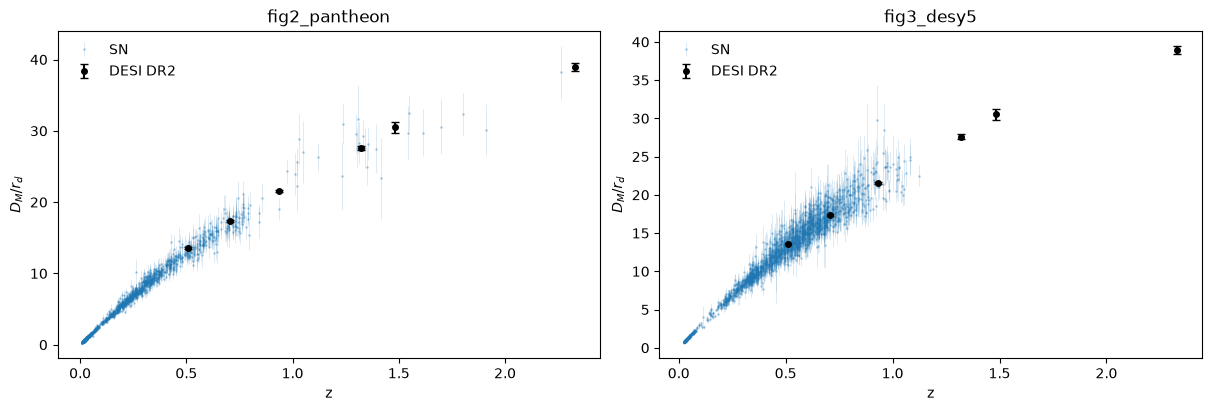

In [3]:
# Audit all 13 observables before selecting the figure-specific submatrices.
desi_config = CONFIGS["fig2_pantheon"]["desi"]
desi_all = pd.read_csv(PROJECT_ROOT / desi_config["mean_file"], sep=r"\s+", comment="#",
                      names=["z", "value", "quantity"])
cov_all = np.loadtxt(PROJECT_ROOT / desi_config["covariance_file"])
assert cov_all.shape == (13, 13)
desi_all.index.name = "source_row"
display(desi_all)
corr_all = cov_all / np.sqrt(np.outer(np.diag(cov_all), np.diag(cov_all)))
audit_rows = []
for quantity in ("DM_over_rs", "DH_over_rs"):
    indices = np.flatnonzero(desi_all.quantity.eq(quantity))
    sub = cov_all[np.ix_(indices, indices)]
    off = sub - np.diag(np.diag(sub))
    audit_rows.append({"quantity": quantity, "indices": indices.tolist(),
                       "nonzero_off_diagonal": int(np.count_nonzero(off)),
                       "max_abs_off_diagonal": float(np.max(np.abs(off)))})
    assert len(indices) == 6
    assert np.count_nonzero(off) == 0
desi_audit = pd.DataFrame(audit_rows)
display(desi_audit)
pair_rows = []
for i, j in zip(*np.where(np.triu(cov_all != 0, k=1))):
    assert desi_all.z.iloc[i] == desi_all.z.iloc[j]
    assert {desi_all.quantity.iloc[i], desi_all.quantity.iloc[j]} == {"DM_over_rs", "DH_over_rs"}
    pair_rows.append({"row_i": int(i), "row_j": int(j), "z": desi_all.z.iloc[i],
                      "covariance": cov_all[i,j], "correlation": corr_all[i,j]})
assert len(pair_rows) == 6
desi_pairs = pd.DataFrame(pair_rows)
display(desi_pairs)

a, b = DATASETS.values()
np.testing.assert_array_equal(a["z"][:6], b["z"][:6])
np.testing.assert_array_equal(a["y"][:6], b["y"][:6])
np.testing.assert_array_equal(a["covariance"][:6,:6], b["covariance"][:6,:6])
for data in DATASETS.values():
    assert np.count_nonzero(data["covariance"][:6,6:]) == 0
    assert len(np.unique(data["row_index"][6:])) == len(data["sn_z"])
bao_check = pd.DataFrame({"tracer": a["id"][:6], "z": a["z"][:6],
    "DM_over_rd": a["y"][:6], "sigma_release": a["sigma"][:6],
    "sigma_paper": [.167,.177,.152,.318,.760,.531]})
bao_check["sigma_difference_percent"] = 100*(bao_check.sigma_release/bao_check.sigma_paper-1)
display(bao_check)

fig, axes = plt.subplots(1,2,figsize=(12,4),constrained_layout=True)
for ax,(name,data) in zip(axes,DATASETS.items()):
    ax.errorbar(data["z"][6:],data["y"][6:],yerr=data["sigma"][6:],
                fmt=".",ms=2,alpha=.25,elinewidth=.4,label="SN")
    ax.errorbar(data["z"][:6],data["y"][:6],yerr=data["sigma"][:6],
                fmt="o",ms=4,color="black",capsize=3,label="DESI DR2")
    ax.set(xlabel="z",ylabel=r"$D_M/r_d$",title=name)
    ax.legend(frameon=False)
plt.show()


## 5. Export and round-trip verification

Each NPZ contains z, y, covariance, sigma, source, row_index, id, sn_observable, sn_observable_covariance, sn_z, and JSON metadata.

The six BAO rows come first, followed by the selected SN rows in original order. Any downstream sorting must reorder both covariance axes. row_index is the zero-based row index in the original source file.

Rerunning this notebook refreshes the same derived output files. The full DESI inventory and covariance audit are exported alongside the prepared datasets.

In [4]:
OUTPUT_DIR = PROJECT_ROOT / "results/08_fig23_data_preparation"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
for name,data in DATASETS.items():
    path = save_standard_dataset(data, OUTPUT_DIR)
    restored = load_standard_dataset(path)
    for key,value in data.items():
        if key != "metadata":
            np.testing.assert_array_equal(restored[key],value)
    print("Saved and round-trip verified:", path.name)
summary.to_csv(OUTPUT_DIR / "sample_summary.csv",index=False)
desi_all.to_csv(OUTPUT_DIR / "desi_observable_inventory.csv",index=True)
desi_audit.to_csv(OUTPUT_DIR / "desi_submatrix_audit.csv",index=False)
desi_pairs.to_csv(OUTPUT_DIR / "desi_correlated_pairs.csv",index=False)
bao_check.to_csv(OUTPUT_DIR / "desi_table1_comparison.csv",index=False)
fig.savefig(OUTPUT_DIR / "prepared_data.png",dpi=160)


Saved and round-trip verified: fig2_pantheon.npz


Saved and round-trip verified: fig3_desy5.npz


## 6. Conclusions and downstream interface

Figure 2 contains 1596 observations; Figure 3 contains 1760. After the dimension, finite-value, symmetry, positive-definiteness, and round-trip checks pass, notebook 09 can load either dataset through:

```python
from src.data_loading import load_standard_dataset
data = load_standard_dataset(path_to_npz)
z, y, covariance = data["z"], data["y"], data["covariance"]
```

The DESI-only DM and DH covariance submatrices are diagonal in the local release; the SN covariance remains full. Keep the public-versus-paper BAO error comparison separate from the small Pantheon+ asymmetry handling.

Data preparation does not establish reproduction of the paper's confidence bands. First-order propagation is approximate at large magnitude errors. Future Monte Carlo work should use the saved magnitude-space joint distribution and a consistent shared ruler treatment. PySR, seed stability, and Monte Carlo settings remain in later notebooks.

See ../notes/learning_notebook.md for the learning notes beginning on 2026-09-16.